# RSM8413: Machine Learning Analytics 
## Group Assignment #2 - eBay Auction Decision Trees
*Team 6 Python Code*

### **[1]: Data Preprocessing**

In [6]:
import pandas as pd

ebay_df = pd.read_excel("../data/eBayAuctions.xlsx", sheet_name="eBay auctions", usecols="A:H")

In [8]:
ebay_df.head()

,Category,Currency,sellerRating,Duration,endDay,ClosePrice,OpenPrice,Competitive?
0,Music/Movie/Game,US,37727.0,7.0,Mon,0.01,0.01,0.0
1,Music/Movie/Game,US,37727.0,7.0,Mon,4.26,0.01,1.0
2,SportingGoods,US,34343.0,1.0,Fri,0.11,0.01,1.0
3,SportingGoods,US,27132.0,5.0,Mon,17.01,0.99,1.0
4,SportingGoods,US,27132.0,5.0,Mon,19.02,0.99,1.0


#### 1A: Initial Preprocessing

First, we check for any null rows in our data. We take the sheet in the Excel file with the data (eBay Auctions) and only take columns A:H to ensure we don't retrieve other unnamed columns.

In [12]:
# number of nulls in each column
ebay_df.isnull().sum()

# show null value rows
print(ebay_df[ebay_df.isnull().any(axis=1)].to_string())

     Category Currency  sellerRating  Duration endDay  ClosePrice  OpenPrice  Competitive?
1972      NaN      NaN           NaN       NaN    NaN         NaN        NaN           NaN
1973      NaN      NaN           NaN       NaN    NaN         NaN        NaN         955.0
1974      NaN      NaN           NaN       NaN    NaN         NaN        NaN        1741.0


After referencing the dataset, the 3 rows that are null are the last 3 rows are aggregations of the data itself and is not part of the dataset. Therefore, it is just a formatting issue and can be dropped. 

In [15]:
clean_ebay_df = ebay_df.dropna().copy()

clean_ebay_df.isnull().sum()

Category        0
Currency        0
sellerRating    0
Duration        0
endDay          0
ClosePrice      0
OpenPrice       0
Competitive?    0
dtype: int64

In [62]:
# check for duplicate rows

# we note that there are duplicate rows. However, there is no ID column to conclude whether or not the auctions are truly repeated. 
# since there is no further identifier, we keep the duplicates. 

clean_ebay_df[clean_ebay_df.duplicated(keep=False)]

,category,currency,seller_rating,duration,end_day,close_price,open_price,competitive
53,Music/Movie/Game,EUR,5701.0,10.0,Sun,1.23,1.23,0.0
54,Music/Movie/Game,EUR,5701.0,10.0,Sun,1.23,1.23,0.0
55,Music/Movie/Game,EUR,5701.0,10.0,Sun,1.23,1.23,0.0
56,Music/Movie/Game,EUR,5701.0,10.0,Sun,1.23,1.23,0.0
71,Pottery/Glass,GBP,5292.0,7.0,Thu,1.78,1.78,0.0
...,...,...,...,...,...,...,...,...
1926,Pottery/Glass,US,993.0,7.0,Sat,99.99,99.99,0.0
1927,Pottery/Glass,US,993.0,7.0,Sat,99.99,99.99,0.0
1928,Pottery/Glass,US,993.0,7.0,Sat,99.99,99.99,0.0
1941,Automotive,US,1364.0,7.0,Tue,128.00,128.00,0.0


In [40]:
# standardize column names 
# lower case + underscore for 2 words, get rid of other characters
clean_ebay_df.columns = (clean_ebay_df.columns.str.replace(r'(?<=[a-z])(?=[A-Z])', '_', regex=True)
                         .str.replace('?', '', regex=False)
                         .str.lower())

#### 1B: Split Train/Test Data

In [42]:
from sklearn.model_selection import train_test_split

features = ["category", "currency", "seller_rating", "duration", "end_day",
            "close_price", "open_price"]

X = clean_ebay_df[features].copy()
y = clean_ebay_df["competitive"].copy()

print("Predictor shape:", X.shape)
print("Target shape:", y.shape)

print("\nData types:")
print(X.dtypes)

Predictor shape: (1972, 7)
Target shape: (1972,)

Data types:
category             str
currency             str
seller_rating    float64
duration         float64
end_day              str
close_price      float64
open_price       float64
dtype: object


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.4,
    random_state=42,
    stratify=y)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (1183, 7)
Testing set: (789, 7)


We  split the train/test set into 60% (1183 observations) training and 40% test (789 observations). 
We set the fixed random state to 42 to ensure reproducibility of every run. 

We'll use the training set to perform any further preprocessing steps and visualizations to grasp a better understanding of the variable distributions. 

#### 1C: Predictor Distribution Check

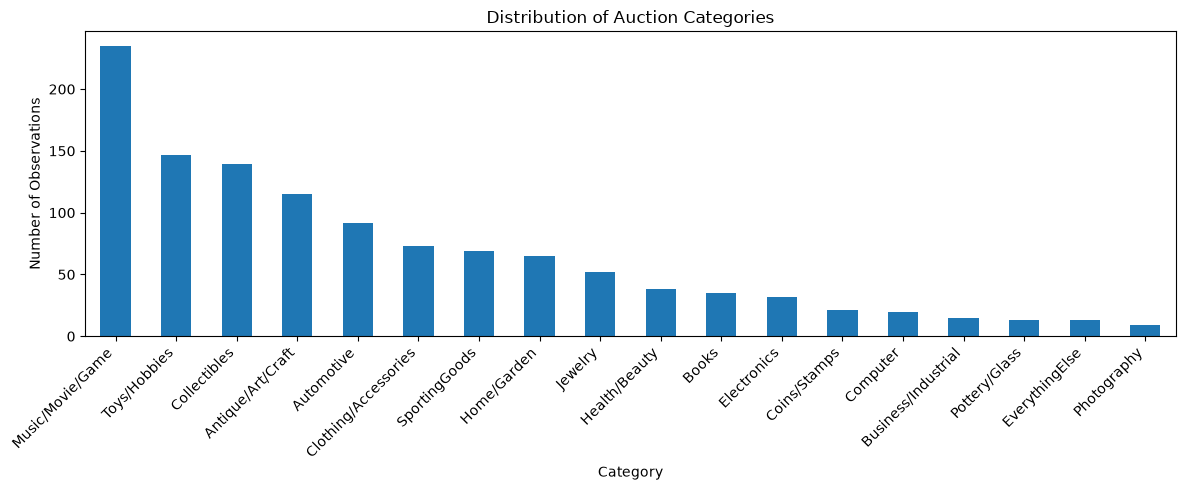

In [46]:
# Category
import matplotlib.pyplot as plt

X_train["category"].value_counts().plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Distribution of Auction Categories")
plt.xlabel("Category")
plt.ylabel("Number of Observations")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

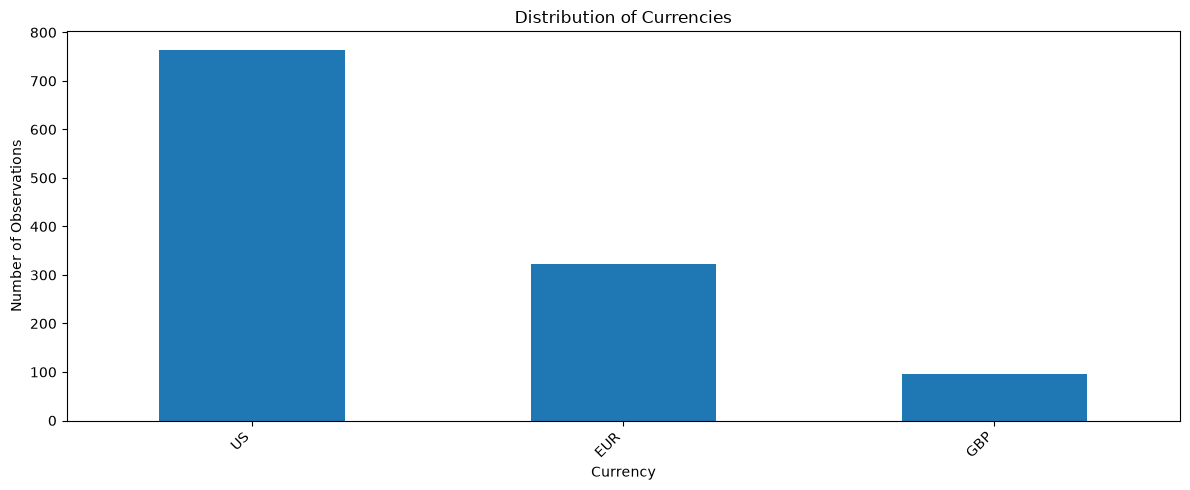

In [49]:
# currency
X_train["currency"].value_counts().plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Distribution of Currencies")
plt.xlabel("Currency")
plt.ylabel("Number of Observations")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

count     1183.000000
mean      3544.847844
std       6058.473199
min          0.000000
25%        578.000000
50%       1719.000000
75%       3380.000000
max      37727.000000
Name: seller_rating, dtype: float64
skew: 3.231030495585379
missing: 0


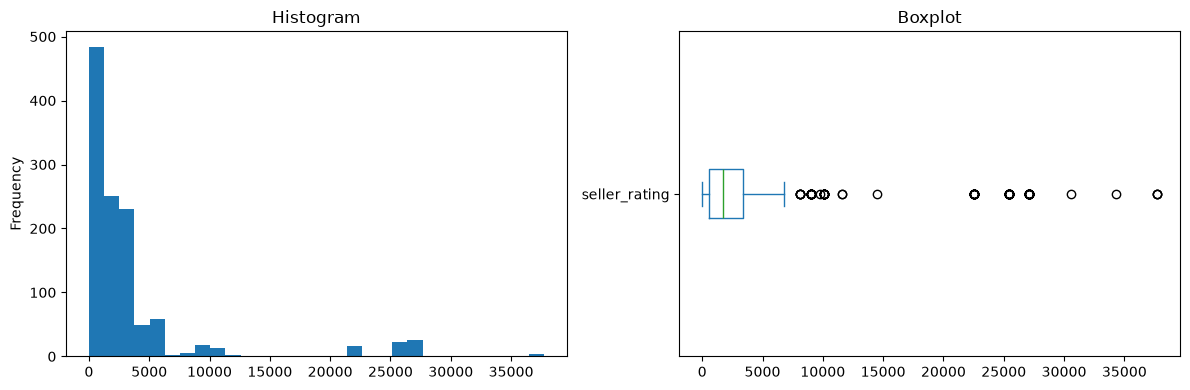

In [51]:
# seller rating 
col = X_train["seller_rating"]

# Summary stats
print(col.describe())
print("skew:", col.skew())
print("missing:", col.isna().sum())

# Histogram + boxplot
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
col.plot(kind="hist", bins=30, ax=axes[0], title="Histogram")
col.plot(kind="box", vert=False, ax=axes[1], title="Boxplot")
plt.tight_layout()
plt.show()

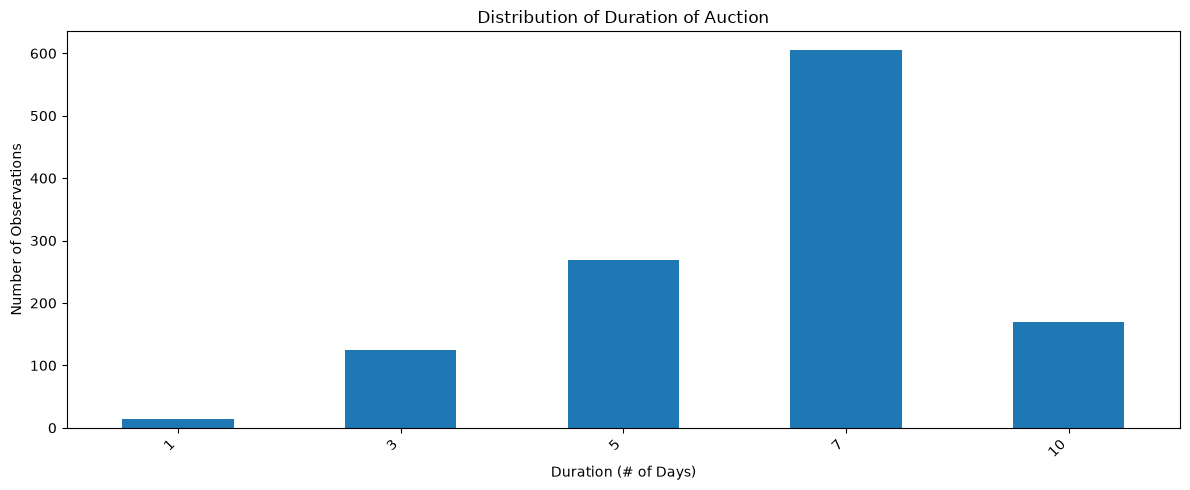

In [53]:
# duration
duration_order = [1, 3, 5, 7, 10]

X_train["duration"].value_counts().reindex(duration_order).plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Distribution of Duration of Auction")
plt.xlabel("Duration (# of Days)")
plt.ylabel("Number of Observations")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

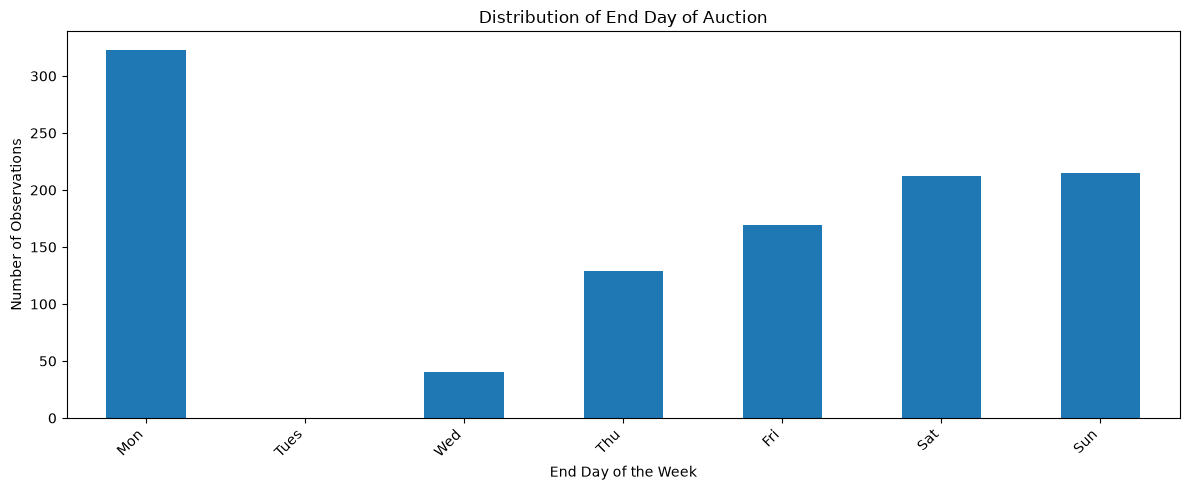

In [56]:
# end day 
day_order = ['Mon', 'Tues', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
X_train["end_day"].value_counts().reindex(day_order).plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Distribution of End Day of Auction")
plt.xlabel("End Day of the Week")
plt.ylabel("Number of Observations")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

count    1183.000000
mean       35.204573
std        86.799829
min         0.010000
25%         4.420000
50%         9.990000
75%        27.000000
max       999.000000
Name: close_price, dtype: float64
skew: 6.1908415212679015
missing: 0


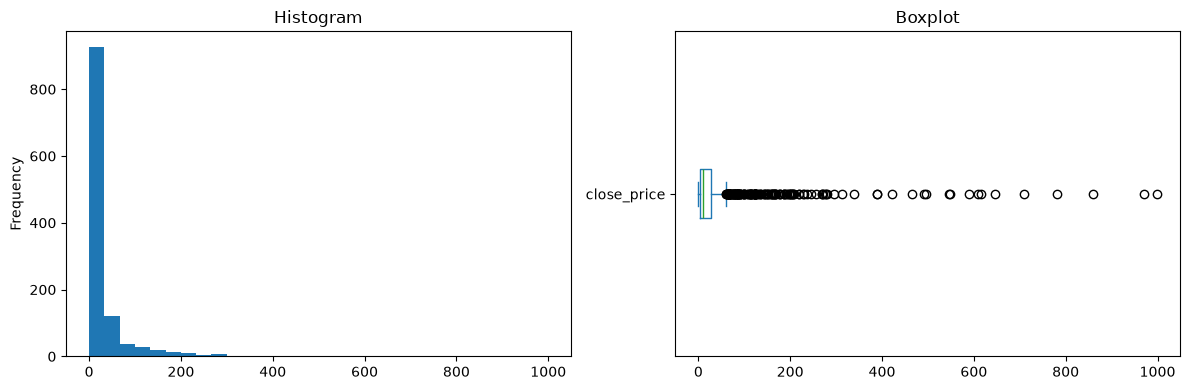

In [57]:
# close price
col = X_train["close_price"]

# Summary stats
print(col.describe())
print("skew:", col.skew())
print("missing:", col.isna().sum())

# Histogram + boxplot
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
col.plot(kind="hist", bins=30, ax=axes[0], title="Histogram")
col.plot(kind="box", vert=False, ax=axes[1], title="Boxplot")
plt.tight_layout()
plt.show()

count    1183.000000
mean       12.520651
std        40.490395
min         0.010000
25%         1.230000
50%         4.440000
75%         9.990000
max       999.000000
Name: open_price, dtype: float64
skew: 15.323018628116992
missing: 0


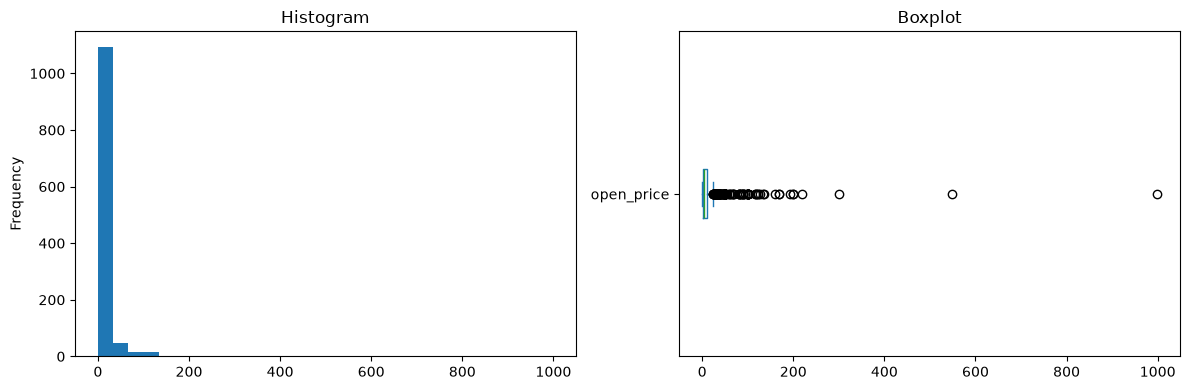

In [58]:
# close price
col = X_train["open_price"]

# Summary stats
print(col.describe())
print("skew:", col.skew())
print("missing:", col.isna().sum())

# Histogram + boxplot
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
col.plot(kind="hist", bins=30, ax=axes[0], title="Histogram")
col.plot(kind="box", vert=False, ax=axes[1], title="Boxplot")
plt.tight_layout()
plt.show()

We conduct an initial distribution analysis to identify potential data quality issues, including numerical predictors with values outside their expected ranges and categorical predictors with inconsistent or non-standardized values.
However, no issues arise when observing the distributions of the variables. 

#### 1D: One-Hot Encoding
Dummy variables are created for the categorical predictors. Numerical predictors are not standardized for the decision tree model, as decision trees use threshold-based splits and are not sensitive to differences in feature scales. In contrast, kNN relies on distance calculations and is sensitive to feature scaling. Therefore, numerical predictors will be standardized when implementing the kNN model later in the analysis.

In [61]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_features = [
    "category",
    "currency",
    "end_day",
    "duration"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ],
    remainder="passthrough"
)

X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

# Check processed dataset dimensions
print("Training shape:", X_train_encoded.shape)
print("Testing shape:", X_test_encoded.shape)

# Check target distribution
print("\nTraining target distribution:")
print(y_train.value_counts())

# ensure response is 0,1 
y_train = y_train.astype(int)
y_test = y_test.astype(int)

Training shape: (1183, 36)
Testing shape: (789, 36)

Training target distribution:
competitive
1    639
0    544
Name: count, dtype: int64
